# Vocoder

## Concept

Un vocoder utilise l'enveloppe fréquentielle d'un flux audio, le signal **modulant** (typiquement une voix), pour moduler (multiplier) l'enveloppe fréquentielle d'une **porteuse** (typiquement une nappe d'accords).

Résultat attendu :

In [1]:
from IPython.display import Audio
import scipy
fs, audio = scipy.io.wavfile.read('./assets/result_3.wav')
display(Audio(audio, rate=fs))

## Instructions

### 1. Banc de filtre

1.1) Créer un banc de filtres IIRs d'ordres, de types et de fréquences :

In [2]:
# define filter: 4 bands
order = 6
filter_specs = [
    {'btype': 'low', 'Wn': 500, 'order': order},
    {'btype': 'bandpass', 'Wn': [500, 2000], 'order': order//2},
    {'btype': 'bandpass', 'Wn': [2000, 4000], 'order': order//2},
    {'btype': 'high', 'Wn': 4000, 'order': order},
]

1.2) à l'aide de la fonction `scipy.signal.freqz` afficher leurs réponses en fréquence :

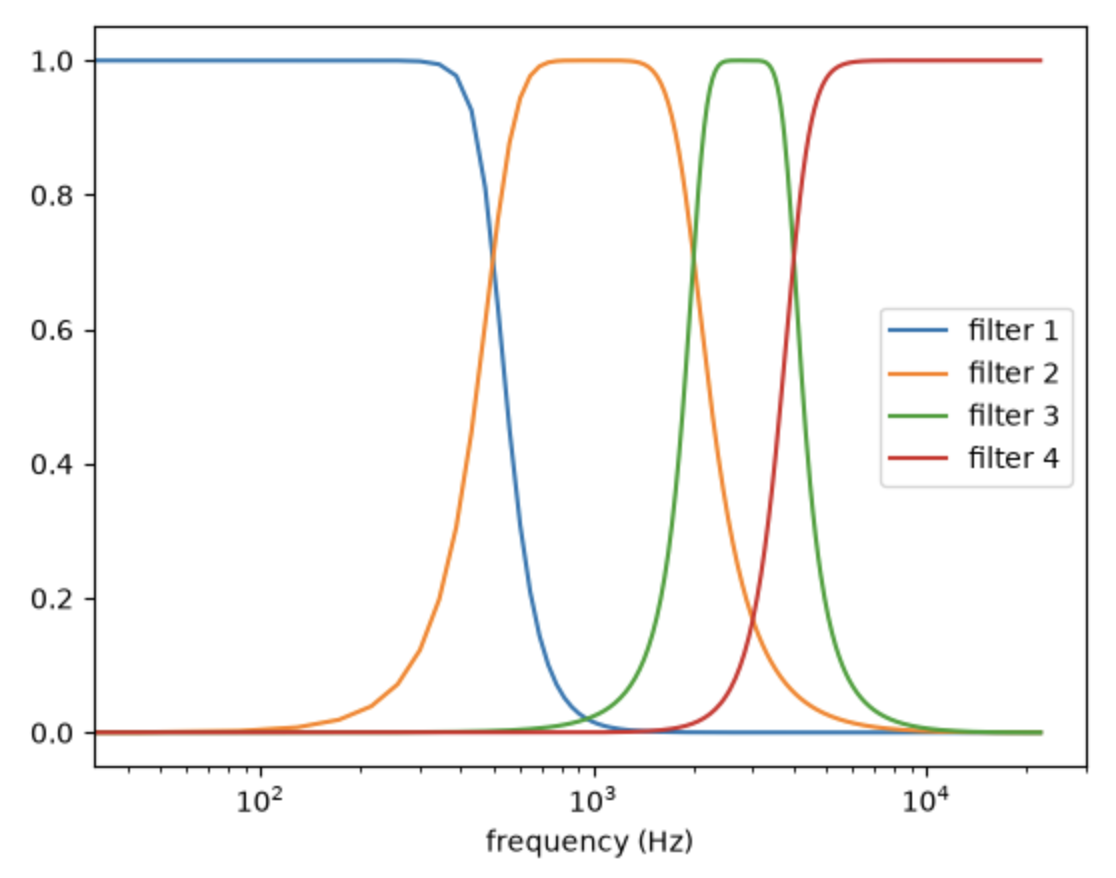

In [3]:
from IPython.display import Image
Image(filename='./assets/result_filters.png', width=600)

1.3) Charger et filtrer le fichier audio speech.wav à l'aide du banc de filtre. Écouter la sortie de chaque bande de fréquence pour valider. Sommer ces sorties et écouter l'audio reconstruit pour vérifier qu'il ressemble à l'original.

### 2. Vocoder

2.1) Charger les fichiers speech.wav (signal modulant) et chords.wav (porteuse), les filtrer avec le banc de filtre. 

2.2) Créer une boucle pour itérer sur le contenu de ces audios (en parralèle sur toutes les bandes de fréquences) par blocks de 512 samples. Pour chaque itération, calculer la RMS (root mean square) pour chaque bande de fréquence du signal modulant. Appliquer ces gains aux bandes de la porteuse. Sommer les bandes de la porteuse pour obtenir un buffer (array) audio mono.

2.3) Pour chaque itération, ajouter ce buffer à votre sortie : un array que vous aurez créé et dimensionné avant d'entrer dans la boucle.

À ce stade vous devriez obtenir :

In [4]:
fs, audio = scipy.io.wavfile.read('./assets/result_1.wav')
display(Audio(audio, rate=fs))

### 3. Zipper noise 

Les craquements (zipper noises) qu'on entend sont liés aux variations abruptes/discontinues du gain entre chaque block / buffer.

3.1) À l'aide du code ci-dessous, appliquer une rampe sur le gain au sein de chaque block : démarrant à la valeur finale du block précédent, s'achevant à la valeur cible du block courant.

3.2) (optionnel) Minimiser la durée de cette rampe pour qu'elle permette de créer un vocodeur réactif même lorsque la taille des blocks choisie est grande devant 512.

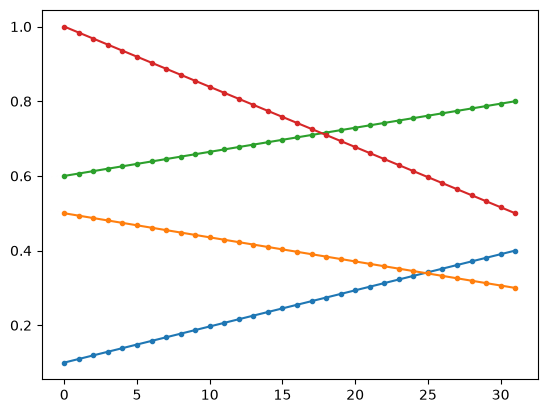

In [5]:
import matplotlib.pyplot as plt
import numpy as np

block_size = 32
gains_old = [0.1, 0.5, 0.6, 1.0]
gains = [0.4, 0.3, 0.8, 0.5]
gains_out = np.linspace(gains_old, gains, block_size)

plt.plot(gains_out, '.-')
plt.show()

À ce stade vous devriez obtenir :

In [6]:
fs, audio = scipy.io.wavfile.read('./assets/result_2.wav')
display(Audio(audio, rate=fs))

### 4. Augmenter le nombre de filtres

4.1) Pour obtenir un résultat plus intelligible (i.e. préserver les formants de la voix), augmenter le nombre de filtres utilisés, e.g. 16 à l'aide du code ci-dessous.

In [7]:
# define N-band filter bank
order = 6
n_bands = 16
edges = np.geomspace(200, 8000, n_bands - 1)
# first band
filter_specs = [ {'btype': 'low', 'Wn': edges[0], 'order': order} ]
# middle band passes
for f_low, f_high in zip(edges[:-1], edges[1:]):
    filter_specs.append({'btype': 'bandpass', 'Wn': [f_low, f_high], 'order': order // 2})
# last band
filter_specs.append({'btype': 'high', 'Wn': edges[-1], 'order': order})

À ce stade vous devriez obtenir l'audio présenté en introduction.

### 5. Cleanup

5.1) Nettoyer et factorisez votre code en encapsulant les opérations redondantes et/ou conceptuellement simple dans des fonctions, par exemple : 
- get_filter_bank_matrix(specs, fs)
- extract_ab_from_matrix(coefs, i)
- plot_filter_bank(coefs, fs)
- apply_filter_bank(audio_in, coefs)

5.2) Commenter votre code.